# E-commerce 360 | Diagnóstico de experiencia y valor comercial

**Caso integrador — Analytics Essentials I · Análisis exploratorio en R**  
**Área de aplicación:** Operaciones y Servicio al Cliente  
**Fuente principal:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## El problema de negocio

Una plataforma de comercio electrónico debe identificar dónde se concentran los incumplimientos logísticos y las experiencias negativas para establecer criterios de atención proporcionales al riesgo observado y al valor comercial.

**Pregunta central:** ¿Qué órdenes deberían recibir atención prioritaria considerando su desempeño logístico, la satisfacción del cliente y su valor comercial?

El diagnóstico en R aborda dos preguntas que sustentan esa decisión:

1. ¿Qué categorías de productos y regiones concentran mayores tasas de entregas tardías y bajas calificaciones?
2. ¿Qué relación existe entre el retraso de entrega, el flete relativo, el valor de compra y la satisfacción del cliente?

La clasificación por orden, sus niveles de prioridad y las acciones asociadas se desarrollan en el notebook de **Python**, a partir de la vista analítica construida aquí.


## Enfoque y alcance

El trabajo sigue una secuencia de negocio: **calidad de fuentes → vista 360 por orden → concentración de problemas → asociaciones con satisfacción → indicadores para la decisión**.

- **Unidad de análisis:** una fila por `order_id`. Ítems y reseñas se agregan antes de realizar las uniones.
- **Cohorte:** órdenes entregadas compradas del **1 de enero de 2017 al 31 de agosto de 2018**, con fechas e importes válidos. En código se utiliza un límite superior exclusivo.
- **Satisfacción:** promedio de reseñas de cada orden, en escala de 1 a 5. Una reseña ausente no equivale a una opinión favorable.
- **Categoría principal:** categoría con mayor valor de productos dentro de la orden, con desempate alfabético. La atribución es descriptiva y no identifica el producto que originó una reseña.
- **Reproducibilidad:** fuente Olist en `data/olist/` o archivo ZIP original; configuración de rutas y fechas centralizada al inicio. Salidas en `salidas/exploratorio_r/`.

El análisis es **descriptivo y asociativo**; no identifica relaciones causales ni estima un modelo predictivo.


## 0. Preparar el entorno

Concentramos rutas, período y umbral mínimo de categoría en una sola celda para que las decisiones sean auditables. El código solo utiliza los paquetes trabajados en el curso y `scales` para el formato de las figuras.


In [1]:
paquetes <- c(
  "readr", "dplyr", "tidyr", "stringr",
  "lubridate", "ggplot2", "purrr", "scales"
)

faltantes <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
if (length(faltantes) > 0) {
  install.packages(faltantes, repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages(invisible(lapply(paquetes, library, character.only = TRUE)))

options(scipen = 999, width = 110)
theme_set(theme_minimal(base_size = 12))

fecha_inicio <- as.Date("2017-01-01")
fecha_fin <- as.Date("2018-09-01")  # Fin exclusivo.
min_pedidos_categoria <- 500L
ruta_csv_manual <- ""  # Opcional: carpeta que contiene los CSV.
ruta_zip_manual <- ""  # Opcional: ruta al ZIP original de Olist.

raiz_proyecto <- if (basename(getwd()) == "notebooks") ".." else "."
ruta_salida <- file.path(raiz_proyecto, "salidas", "exploratorio_r")
dir.create(ruta_salida, recursive = TRUE, showWarnings = FALSE)


## 1. Comprender y validar las fuentes

Una orden puede contener varios productos y varias reseñas. Si uniéramos esas tablas sin agregarlas antes, **multiplicaríamos filas e importes**, alterando las tasas y conclusiones. Por eso empezamos reconociendo la granularidad de cada fuente.

| Fuente | Llave y nivel de detalle | Papel en el análisis |
|---|---|---|
| `orders` | Una fila por `order_id` | Fechas y estado logístico |
| `items` | Varios ítems por orden | Valor de productos y flete |
| `reviews` | Una o más reseñas por orden | Satisfacción reportada |
| `customers` | Una fila por `customer_id` | Estado y macrorregión de destino |
| `products` | Una fila por `product_id` | Categoría del producto |

La tabla de traducción de categorías es opcional. Para preservar identificadores, los CSV se cargan inicialmente como texto; los tipos se convierten explícitamente después.


In [2]:
archivos <- c(
  orders = "olist_orders_dataset.csv",
  items = "olist_order_items_dataset.csv",
  reviews = "olist_order_reviews_dataset.csv",
  customers = "olist_customers_dataset.csv",
  products = "olist_products_dataset.csv",
  translation = "product_category_name_translation.csv"
)
obligatorios <- archivos[names(archivos) != "translation"]

carpetas <- unique(c(
  ruta_csv_manual, file.path(raiz_proyecto, "data", "olist"),
  "../data/olist", "data/olist", "/content", "."
))
carpetas <- carpetas[nzchar(carpetas) & dir.exists(carpetas)]
contiene_csv <- function(ruta) all(file.exists(file.path(ruta, obligatorios)))
validas <- carpetas[vapply(carpetas, contiene_csv, logical(1))]

if (nzchar(ruta_csv_manual) && !contiene_csv(ruta_csv_manual)) {
  stop("La carpeta manual no contiene los cinco CSV obligatorios.")
}

if (length(validas) > 0 && !nzchar(ruta_zip_manual)) {
  ruta_datos <- validas[1]
  origen <- ruta_datos
} else {
  carpetas_zip <- unique(c(raiz_proyecto, "../data", "data", "/content", "."))
  carpetas_zip <- carpetas_zip[dir.exists(carpetas_zip)]
  candidatos <- unique(unlist(lapply(carpetas_zip, function(ruta) {
    list.files(ruta, pattern = "\\.zip$", full.names = TRUE, ignore.case = TRUE)
  })))
  if (nzchar(ruta_zip_manual)) candidatos <- ruta_zip_manual

  es_zip_olist <- function(ruta) {
    if (!file.exists(ruta)) return(FALSE)
    tryCatch({
      entradas <- basename(utils::unzip(ruta, list = TRUE)$Name)
      all(obligatorios %in% entradas)
    }, error = function(e) FALSE)
  }
  candidatos <- candidatos[vapply(candidatos, es_zip_olist, logical(1))]
  if (length(candidatos) != 1) {
    stop("No se encontró un ZIP de Olist inequívoco. Indica ruta_zip_manual o usa data/olist/.")
  }

  lista_zip <- utils::unzip(candidatos[1], list = TRUE)$Name
  entradas <- vapply(obligatorios, function(nombre) {
    coincidencias <- lista_zip[basename(lista_zip) == nombre]
    if (length(coincidencias) != 1) stop("Archivo faltante o duplicado: ", nombre)
    coincidencias
  }, character(1))
  opcion_traduccion <- lista_zip[basename(lista_zip) == archivos["translation"]]
  if (length(opcion_traduccion) == 1) entradas <- c(entradas, opcion_traduccion)

  ruta_datos <- tempfile("olist_r_")
  dir.create(ruta_datos)
  utils::unzip(candidatos[1], files = unname(entradas),
               exdir = ruta_datos, junkpaths = TRUE)
  origen <- candidatos[1]
}

disponibles <- archivos[file.exists(file.path(ruta_datos, archivos))]
tablas <- purrr::map(disponibles, function(nombre) {
  readr::read_csv(
    file.path(ruta_datos, nombre),
    col_types = readr::cols(.default = readr::col_character()),
    na = c("", "NA"), show_col_types = FALSE, progress = FALSE
  )
})
cat("Fuente:", origen, "\nTablas cargadas:", paste(names(tablas), collapse = ", "), "\n")


Fuente: ../data/olist 
Tablas cargadas: orders, items, reviews, customers, products, translation 


### 1.1. Diagnóstico antes de limpiar

Cuantificamos filas, columnas, celdas vacías y duplicados **exactos**. Que `order_id` se repita en ítems o reseñas es normal; el control de unicidad debe aplicarse según la llave de cada tabla, no sobre cualquier repetición del identificador.


In [3]:
diagnostico <- purrr::imap_dfr(tablas, function(datos, nombre) {
  tibble(
    tabla = nombre, filas = nrow(datos), columnas = ncol(datos),
    celdas_nulas = sum(is.na(datos)),
    duplicados_exactos = sum(duplicated(datos)),
    ordenes_unicas = if ("order_id" %in% names(datos))
      n_distinct(datos$order_id) else NA_integer_
  )
})
print(diagnostico, n = Inf)

cat("\nMuestra de orders:\n")
print(tablas$orders %>% select(order_id, order_status, order_purchase_timestamp) %>% head(3))


# A tibble: 6 × 6
  tabla        filas columnas celdas_nulas duplicados_exactos ordenes_unicas
  <chr>        <int>    <int>        <int>              <int>          <int>
1 orders       99441        8         4908                  0          99441
2 items       112650        7            0                  0          98666
3 reviews      99224        7       145914                  0          98673
4 customers    99441        5            0                  0             NA
5 products     32951        9         2448                  0             NA
6 translation     71        2            0                  0             NA

Muestra de orders:
# A tibble: 3 × 3
  order_id                         order_status order_purchase_timestamp
  <chr>                            <chr>        <chr>                   
1 e481f51cbdc54678b7cc49136f2d6af7 delivered    2017-10-02 10:56:33     
2 53cdb2fc8bc7dce0b6741e2150273451 delivered    2018-07-24 20:41:37     
3 47770eb9100c2d0c44946d9cf07ec65d d

### 1.2. Limpieza y registro de decisiones

Estandarizamos textos, convertimos fechas e importes y eliminamos únicamente filas idénticas. Después validamos llaves y rangos. La tabla de reglas registra **qué se corrigió, cuántos registros resultaron afectados y por qué**: la limpieza forma parte de la evidencia, no es una operación invisible.


In [4]:
orders_sin_duplicados <- tablas$orders %>% distinct()
orders <- orders_sin_duplicados %>%
  mutate(
    order_status = str_to_lower(str_squish(order_status)),
    order_purchase_timestamp = ymd_hms(order_purchase_timestamp, quiet = TRUE, tz = "UTC"),
    order_delivered_customer_date = ymd_hms(order_delivered_customer_date, quiet = TRUE, tz = "UTC"),
    order_estimated_delivery_date = ymd_hms(order_estimated_delivery_date, quiet = TRUE, tz = "UTC")
  )

items <- tablas$items %>%
  distinct() %>%
  mutate(price = parse_double(price), freight_value = parse_double(freight_value))

reviews <- tablas$reviews %>%
  distinct() %>%
  mutate(review_score = parse_double(review_score))

customers <- tablas$customers %>%
  distinct() %>%
  mutate(customer_state = str_to_upper(str_squish(customer_state)))

products <- tablas$products %>%
  distinct() %>%
  mutate(product_category_name = na_if(str_squish(product_category_name), ""))

translation <- if ("translation" %in% names(tablas)) {
  tablas$translation %>% distinct()
} else {
  tibble(product_category_name = character(), product_category_name_english = character())
}

stopifnot(
  !anyNA(orders$order_id), !anyDuplicated(orders$order_id),
  !anyDuplicated(customers$customer_id), !anyDuplicated(products$product_id),
  !anyDuplicated(items[c("order_id", "order_item_id")]),
  !anyDuplicated(reviews[c("order_id", "review_id")]),
  !anyDuplicated(translation$product_category_name),
  all(items$order_id %in% orders$order_id),
  all(reviews$order_id %in% orders$order_id),
  all(!is.na(items$price) & items$price >= 0),
  all(!is.na(items$freight_value) & items$freight_value >= 0),
  all(is.na(reviews$review_score) | between(reviews$review_score, 1, 5))
)

reglas_limpieza <- tibble(
  problema = c("Duplicados exactos: orders", "Duplicados exactos: items",
               "Duplicados exactos: reviews", "Estado con formato irregular",
               "Categoría de producto ausente", "Reseña sin calificación",
               "Fecha de compra no interpretable"),
  regla = c("distinct()", "distinct()", "distinct()",
            "str_to_lower(str_squish())", "Conservar como sin_categoria",
            "Mantener NA; no imputar", "ymd_hms(); mantener NA y auditar filtro"),
  registros_afectados = c(
    nrow(tablas$orders) - nrow(orders),
    nrow(tablas$items) - nrow(items),
    nrow(tablas$reviews) - nrow(reviews),
    sum(tablas$orders$order_status != str_to_lower(str_squish(tablas$orders$order_status)), na.rm = TRUE),
    sum(is.na(products$product_category_name)),
    sum(is.na(reviews$review_score)),
    sum(!is.na(orders_sin_duplicados$order_purchase_timestamp) &
          is.na(orders$order_purchase_timestamp))
  ),
  decision = c("Eliminar filas idénticas", "Eliminar filas idénticas",
               "Eliminar filas idénticas", "Estandarizar etiqueta",
               "Conservar con categoría desconocida", "Excluir solo del denominador de satisfacción",
               "No forzar fecha; excluir en cohorte temporal")
)
print(reglas_limpieza, n = Inf)


# A tibble: 7 × 4
  problema                         regla                                   registros_afectados decision       
  <chr>                            <chr>                                                 <int> <chr>          
1 Duplicados exactos: orders       distinct()                                                0 Eliminar filas…
2 Duplicados exactos: items        distinct()                                                0 Eliminar filas…
3 Duplicados exactos: reviews      distinct()                                                0 Eliminar filas…
4 Estado con formato irregular     str_to_lower(str_squish())                                0 Estandarizar e…
5 Categoría de producto ausente    Conservar como sin_categoria                            610 Conservar con …
6 Reseña sin calificación          Mantener NA; no imputar                                   0 Excluir solo d…
7 Fecha de compra no interpretable ymd_hms(); mantener NA y auditar filtro                   0

## 2. Construir una vista 360 sin duplicar órdenes

Necesitamos reunir logística, categoría, reseñas y dinero en una misma unidad. Para mantener **una fila por orden**, primero resumimos los ítems y las reseñas por separado.

- **Valor de productos (R$):** suma de `price`; es valor vendido observado, no margen.
- **Flete (R$):** suma de `freight_value`.
- **Valor total observado (R$):** productos + flete; no reemplaza los pagos ni representa utilidad.
- **Satisfacción:** media de `review_score` disponible para cada orden (escala 1–5).
- **Categoría principal:** la de mayor valor de productos dentro de la orden; no atribuye la reseña a un producto específico.


In [5]:
productos_categoria <- products %>%
  select(product_id, product_category_name) %>%
  left_join(translation, by = "product_category_name", relationship = "many-to-one") %>%
  mutate(categoria = coalesce(product_category_name_english,
                              product_category_name, "sin_categoria")) %>%
  select(product_id, categoria)

items_enriquecidos <- items %>%
  left_join(productos_categoria, by = "product_id", relationship = "many-to-one") %>%
  mutate(categoria = coalesce(categoria, "sin_categoria"))

categoria_principal <- items_enriquecidos %>%
  group_by(order_id, categoria) %>%
  summarise(valor_categoria = sum(price), .groups = "drop") %>%
  arrange(order_id, desc(valor_categoria), categoria) %>%
  group_by(order_id) %>%
  slice_head(n = 1) %>%
  ungroup() %>%
  transmute(order_id, categoria_orden = categoria)

items_orden <- items_enriquecidos %>%
  group_by(order_id) %>%
  summarise(
    valor_productos = sum(price), flete = sum(freight_value),
    n_items = n(), n_categorias = n_distinct(categoria), .groups = "drop"
  ) %>%
  left_join(categoria_principal, by = "order_id", relationship = "one-to-one")

reviews_orden <- reviews %>%
  group_by(order_id) %>%
  summarise(
    satisfaccion = if (all(is.na(review_score))) NA_real_
      else mean(review_score, na.rm = TRUE),
    n_reviews = n(), .groups = "drop"
  )

stopifnot(
  !anyDuplicated(items_orden$order_id), !anyDuplicated(reviews_orden$order_id),
  isTRUE(all.equal(sum(items$price), sum(items_orden$valor_productos))),
  isTRUE(all.equal(sum(items$freight_value), sum(items_orden$flete)))
)


### 2.1. Uniones seguras y localización del cliente

Cruzamos las tablas resumidas y comprobamos después de cada unión que no cambia el número de órdenes ni aparece un `order_id` duplicado. La región proviene del **estado del cliente**, no del vendedor: mide dónde se recibió la compra, no desde dónde se despachó.


In [6]:
validar_vista <- function(datos, filas_esperadas, etapa) {
  if (nrow(datos) != filas_esperadas || anyDuplicated(datos$order_id) > 0) {
    stop("La unión alteró la granularidad de orden: ", etapa)
  }
  invisible(datos)
}

vista_orden <- orders %>%
  left_join(items_orden, by = "order_id", relationship = "one-to-one")
validar_vista(vista_orden, nrow(orders), "items")

vista_orden <- vista_orden %>%
  left_join(reviews_orden, by = "order_id", relationship = "one-to-one")
validar_vista(vista_orden, nrow(orders), "reviews")

vista_orden <- vista_orden %>%
  left_join(customers %>% select(customer_id, customer_state),
            by = "customer_id", relationship = "many-to-one")
validar_vista(vista_orden, nrow(orders), "customers")

regiones <- list(
  Norte = c("AC", "AM", "AP", "PA", "RO", "RR", "TO"),
  Nordeste = c("AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"),
  `Centro-Oeste` = c("DF", "GO", "MS", "MT"),
  Sudeste = c("ES", "MG", "RJ", "SP"),
  Sur = c("PR", "RS", "SC")
)
mapa_regiones <- purrr::imap_dfr(regiones, ~ tibble(customer_state = .x, region = .y))
stopifnot(!anyDuplicated(mapa_regiones$customer_state))

vista_orden <- vista_orden %>%
  left_join(mapa_regiones, by = "customer_state", relationship = "many-to-one") %>%
  mutate(region = coalesce(region, "Sin región"),
         n_reviews = coalesce(n_reviews, 0L))
validar_vista(vista_orden, nrow(orders), "región")

vista_orden %>%
  summarise(
    filas = n(), ordenes_unicas = n_distinct(order_id),
    sin_items = sum(is.na(valor_productos)),
    sin_resena = sum(is.na(satisfaccion)),
    con_varias_categorias = sum(n_categorias > 1, na.rm = TRUE)
  ) %>% print()


# A tibble: 1 × 5
  filas ordenes_unicas sin_items sin_resena con_varias_categorias
  <int>          <int>     <int>      <int>                 <int>
1 99441          99441       775        768                   786


### 2.2. Definir la cohorte y los indicadores

Solo comparamos órdenes entregadas dentro del período común, con fechas e importes válidos. Los filtros quedan cuantificados para que sea visible cuántas órdenes entran al análisis.

**Indicadores clave:**

- `desfase_dias`: días calendario entre la fecha real y la estimada de entrega; es negativo si llegó antes.
- `dias_retraso`: máximo entre `desfase_dias` y cero; mide únicamente días posteriores a la fecha estimada.
- `entrega_tardia`: `desfase_dias > 0`.
- `flete_relativo`: flete / valor de productos, guardado como **proporción**.
- `calificacion_baja`: satisfacción media por orden ≤ 2. Sin reseña permanece como valor ausente.

**Denominadores:** la tasa de tardías utiliza todas las órdenes válidas de cada grupo; la de baja calificación solo las órdenes con reseña. No son porcentajes calculados sobre la misma cantidad de observaciones.


In [7]:
vista_orden <- vista_orden %>%
  mutate(
    fecha_compra = as.Date(order_purchase_timestamp),
    mes = as.Date(floor_date(order_purchase_timestamp, "month")),
    valor_total = valor_productos + flete,
    dias_entrega = as.numeric(difftime(
      order_delivered_customer_date, order_purchase_timestamp, units = "days"
    )),
    desfase_dias = as.numeric(
      as.Date(order_delivered_customer_date) - as.Date(order_estimated_delivery_date)
    ),
    dias_retraso = pmax(desfase_dias, 0),
    entrega_tardia = desfase_dias > 0,
    flete_relativo = if_else(
      !is.na(valor_productos) & valor_productos > 0,
      flete / valor_productos, NA_real_
    ),
    calificacion_baja = if_else(
      is.na(satisfaccion), NA, satisfaccion <= 2
    )
  )

base_entregadas <- vista_orden %>% filter(order_status == "delivered")
base_periodo <- base_entregadas %>%
  filter(fecha_compra >= fecha_inicio, fecha_compra < fecha_fin)
base_fechas <- base_periodo %>%
  filter(!is.na(dias_entrega), dias_entrega >= 0, !is.na(desfase_dias))
base_analisis <- base_fechas %>%
  filter(!is.na(valor_productos), valor_productos > 0,
         !is.na(flete), flete >= 0)

stopifnot(nrow(base_analisis) >= 1000, !anyDuplicated(base_analisis$order_id))

filtros <- tibble(
  paso = c("Fuente", "Entregadas", "Período de compra", "Fechas válidas", "Importes válidos"),
  ordenes = c(nrow(vista_orden), nrow(base_entregadas), nrow(base_periodo),
              nrow(base_fechas), nrow(base_analisis))
) %>%
  mutate(excluidas_en_paso = lag(ordenes, default = first(ordenes)) - ordenes)

print(filtros)
cat("Cobertura de reseñas:",
    scales::percent(mean(!is.na(base_analisis$satisfaccion)), accuracy = 0.1), "\n")


# A tibble: 5 × 3
  paso              ordenes excluidas_en_paso
  <chr>               <int>             <int>
1 Fuente              99441                 0
2 Entregadas          96478              2963
3 Período de compra   96211               267
4 Fechas válidas      96203                 8
5 Importes válidos    96203                 0
Cobertura de reseñas: 99.3% 


## 3. ¿Dónde se concentran los problemas?

**Pregunta secundaria 1:** ¿Qué categorías y regiones presentan tasas elevadas de entregas tardías y bajas calificaciones?

Calculamos por segmento tanto las **tasas** como los **conteos**. Una tasa elevada indica mayor incidencia relativa; un número elevado de casos señala volumen potencial de atención. No debemos confundir ambas lecturas.

Para evitar comparaciones inestables, seleccionamos categorías con al menos **500 órdenes** y mostramos la unión de las cuatro mayores tasas de cada indicador. Incluimos las cinco macrorregiones de destino disponibles.


In [8]:
resumir_segmento <- function(datos, variable) {
  datos %>%
    group_by(across(all_of(variable))) %>%
    summarise(
      ordenes = n(), ordenes_con_resena = sum(!is.na(satisfaccion)),
      tardias = sum(entrega_tardia),
      bajas = sum(calificacion_baja, na.rm = TRUE),
      tasa_tardia = tardias / ordenes,
      tasa_baja = if_else(ordenes_con_resena > 0,
                           bajas / ordenes_con_resena, NA_real_),
      .groups = "drop"
    )
}

resumen_categorias <- resumir_segmento(base_analisis, "categoria_orden")
resumen_regiones <- resumir_segmento(base_analisis, "region")

cat("Categorías comparables con mayor tasa de calificaciones bajas:\n")
resumen_categorias %>%
  filter(ordenes >= min_pedidos_categoria, categoria_orden != "sin_categoria") %>%
  arrange(desc(tasa_baja)) %>%
  select(categoria_orden, ordenes, tardias, bajas, tasa_tardia, tasa_baja) %>%
  head(10) %>% print()

cat("\nRegiones (tasas y volumen):\n")
resumen_regiones %>% arrange(desc(tasa_tardia)) %>% print(n = Inf)


Categorías comparables con mayor tasa de calificaciones bajas:
# A tibble: 10 × 6
   categoria_orden                 ordenes tardias bajas tasa_tardia tasa_baja
   <chr>                             <int>   <int> <int>       <dbl>     <dbl>
 1 office_furniture                   1245     101   268      0.0811     0.217
 2 bed_bath_table                     9202     687  1431      0.0747     0.157
 3 furniture_decor                    6142     448   901      0.0729     0.148
 4 computers_accessories              6500     416   934      0.064      0.144
 5 telephony                          4066     291   563      0.0716     0.139
 6 baby                               2748     224   374      0.0815     0.137
 7 watches_gifts                      5471     406   740      0.0742     0.136
 8 electronics                        2502     192   324      0.0767     0.130
 9 auto                               3783     278   480      0.0735     0.127
10 construction_tools_construction     727      5

### 3.1. Comparación por categoría y región

Las dos matrices presentan **entregas tardías**, **calificaciones bajas** y **volumen de órdenes**. Cada tasa emplea su propio denominador: todas las órdenes válidas para tardanzas y únicamente las órdenes con reseña para satisfacción.

La intensidad de color se normaliza **por columna y por matriz** para destacar diferencias internas. Por ello, el color no es directamente comparable entre indicadores: la magnitud se interpreta leyendo el porcentaje de cada celda. Se seleccionan categorías con 500 órdenes o más y se muestran todas las macrorregiones registradas.


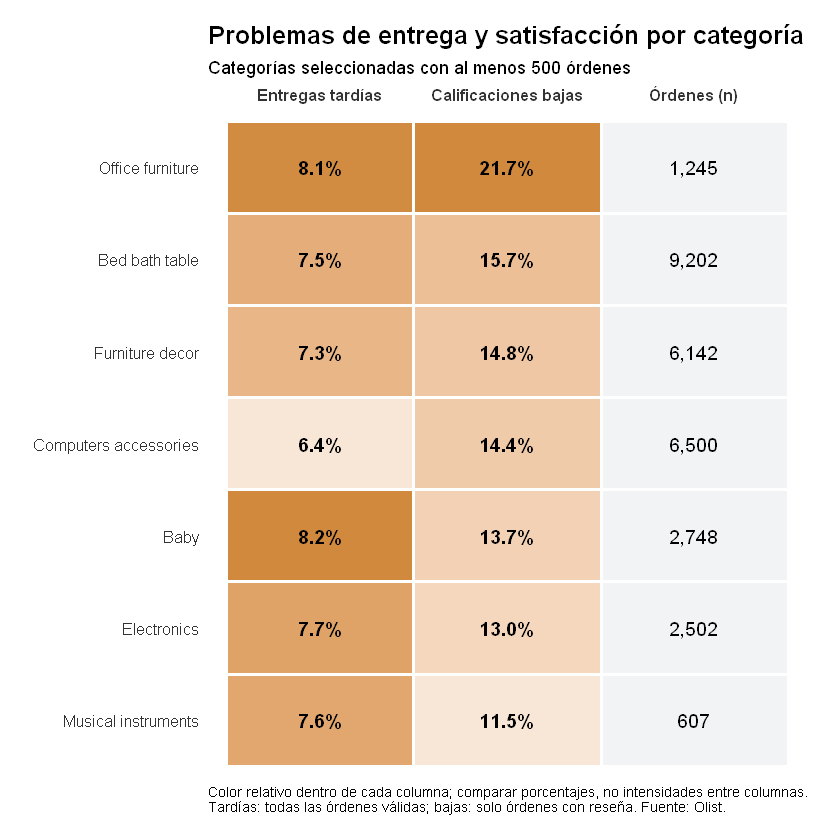

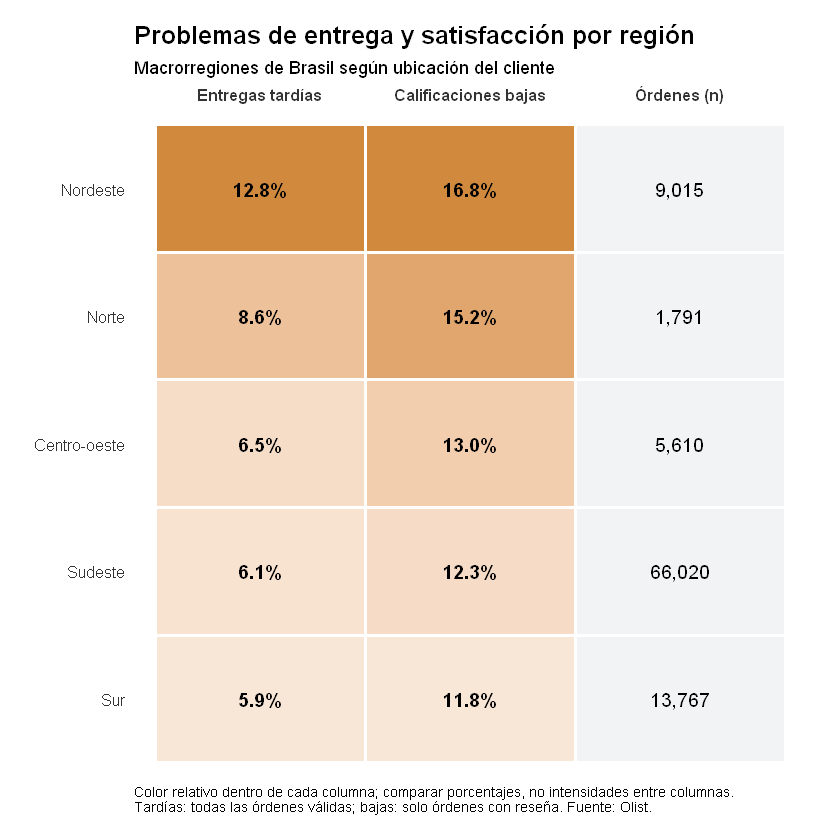

In [9]:
# R01 — Dos matrices de calor: categorías y regiones.
# El color se normaliza dentro de cada indicador; los porcentajes no se modifican.

categorias_elegibles <- resumen_categorias %>%
  filter(
    ordenes >= min_pedidos_categoria,
    categoria_orden != "sin_categoria",
    !is.na(tasa_baja)
  )

categorias_top <- bind_rows(
  categorias_elegibles %>% slice_max(tasa_tardia, n = 4, with_ties = FALSE),
  categorias_elegibles %>% slice_max(tasa_baja, n = 4, with_ties = FALSE)
) %>%
  distinct(categoria_orden, .keep_all = TRUE)

segmentos_figura <- bind_rows(
  categorias_top %>% transmute(
    panel = "Categorías", nombre = categoria_orden,
    ordenes, tasa_tardia, tasa_baja
  ),
  resumen_regiones %>%
    filter(region != "Sin región") %>%
    transmute(
      panel = "Regiones", nombre = region,
      ordenes, tasa_tardia, tasa_baja
    )
)

crear_matriz_calor <- function(datos, titulo, subtitulo) {
  tabla <- datos %>%
    mutate(
      segmento = str_to_sentence(str_replace_all(nombre, "_", " "))
    ) %>%
    arrange(desc(tasa_baja)) %>%
    mutate(segmento = factor(segmento, levels = rev(unique(segmento))))

  tasas <- tabla %>%
    select(segmento, tasa_tardia, tasa_baja) %>%
    pivot_longer(
      cols = c(tasa_tardia, tasa_baja),
      names_to = "indicador", values_to = "tasa"
    ) %>%
    group_by(indicador) %>%
    mutate(intensidad = scales::rescale(tasa, to = c(0.12, 1))) %>%
    ungroup() %>%
    mutate(
      indicador = recode(
        indicador,
        tasa_tardia = "Entregas tardías",
        tasa_baja = "Calificaciones bajas"
      ),
      etiqueta = if_else(
        is.na(tasa), "s/d", scales::percent(tasa, accuracy = 0.1)
      )
    )

  ggplot(tasas, aes(x = indicador, y = segmento)) +
    geom_tile(aes(fill = intensidad), color = "white", linewidth = 1) +
    geom_text(aes(label = etiqueta), size = 4, fontface = "bold") +
    geom_tile(
      data = tabla,
      aes(x = "Órdenes (n)", y = segmento),
      inherit.aes = FALSE,
      fill = "#F1F3F5", color = "white", linewidth = 1
    ) +
    geom_text(
      data = tabla,
      aes(
        x = "Órdenes (n)", y = segmento,
        label = scales::comma(ordenes)
      ),
      inherit.aes = FALSE, size = 4
    ) +
    scale_x_discrete(
      limits = c("Entregas tardías", "Calificaciones bajas", "Órdenes (n)"),
      position = "top"
    ) +
    scale_fill_gradient(
      low = "#FBF3EC", high = "#D18A3D",
      limits = c(0, 1), na.value = "#EEEEEE", guide = "none"
    ) +
    labs(
      title = titulo, subtitle = subtitulo, x = NULL, y = NULL,
      caption = paste(
        "Color relativo dentro de cada columna; comparar porcentajes, no intensidades entre columnas.",
        "Tardías: todas las órdenes válidas; bajas: solo órdenes con reseña. Fuente: Olist.",
        sep = "\n"
      )
    ) +
    theme_minimal(base_size = 12) +
    theme(
      plot.title = element_text(face = "bold", size = 15),
      plot.subtitle = element_text(size = 11),
      axis.text.x = element_text(face = "bold", color = "#333333"),
      axis.text.y = element_text(color = "#333333"),
      panel.grid = element_blank(),
      plot.caption = element_text(hjust = 0, size = 8.5),
      plot.margin = margin(15, 20, 15, 15)
    )
}

grafico_categorias <- segmentos_figura %>%
  filter(panel == "Categorías") %>%
  crear_matriz_calor(
    "Problemas de entrega y satisfacción por categoría",
    "Categorías seleccionadas con al menos 500 órdenes"
  )

grafico_regiones <- segmentos_figura %>%
  filter(panel == "Regiones") %>%
  crear_matriz_calor(
    "Problemas de entrega y satisfacción por región",
    "Macrorregiones de Brasil según ubicación del cliente"
  )

print(grafico_categorias)
print(grafico_regiones)


### 3.2. Hallazgos por segmento

**La región Nordeste reúne las mayores incidencias relativas en ambos indicadores:** **12,8 %** de entregas tardías y **16,8 %** de calificaciones bajas en **9.015 órdenes**. La coincidencia señala una zona relevante para revisar el desempeño del servicio, sin atribuir la diferencia exclusivamente a la ubicación.

Por categorías, **Office furniture** registra **21,7 %** de calificaciones bajas en **1.245 órdenes**. En contraste, **Bed bath table** tiene una tasa menor (**15,7 %**) pero un volumen considerablemente mayor (**9.202 órdenes**). Esto distingue **incidencia relativa** de **cantidad potencial de casos**.

Estas comparaciones ubican segmentos con señales desfavorables; para decidir qué órdenes atender resulta necesario relacionar las señales logísticas y comerciales con la experiencia observada.


## 4. ¿Qué variables se asocian con la insatisfacción?

**Pregunta secundaria 2:** ¿Cómo se relacionan el retraso, el flete relativo y el valor de compra con la satisfacción reportada?

Comparamos tasas de calificación baja por tramos de retraso y flete, complementadas con cuartiles de valor. Conservamos la misma cohorte y una función común de agregación, para no cambiar inadvertidamente los denominadores.

Los tramos son **descriptivos**: todavía no son umbrales aprobados para una política de atención. Las relaciones numéricas se contrastarán con Spearman, sin interpretar asociación como causalidad.


In [10]:
base_analisis <- base_analisis %>%
  mutate(
    tramo_retraso = cut(
      dias_retraso, breaks = c(-Inf, 0, 3, 7, 14, Inf),
      labels = c("A tiempo", "1–3 días", "4–7 días", "8–14 días", "15+ días")
    ),
    tramo_flete = cut(
      flete_relativo, breaks = c(-Inf, 0.10, 0.20, 0.40, Inf),
      labels = c("Hasta 10%", ">10–20%", ">20–40%", "Más de 40%")
    ),
    cuartil_valor = paste0("Q", ntile(valor_productos, 4))
  )

resumir_experiencia <- function(datos, grupo) {
  datos %>%
    group_by(across(all_of(grupo))) %>%
    summarise(
      ordenes = n(), con_resena = sum(!is.na(satisfaccion)),
      calificaciones_bajas = sum(calificacion_baja, na.rm = TRUE),
      tasa_baja = if_else(con_resena > 0,
                          calificaciones_bajas / con_resena, NA_real_),
      nota_media = if (all(is.na(satisfaccion))) NA_real_
        else mean(satisfaccion, na.rm = TRUE),
      .groups = "drop"
    )
}

grupos <- c("tramo_retraso", "tramo_flete", "cuartil_valor")
resumenes <- setNames(
  purrr::map(grupos, ~ resumir_experiencia(base_analisis, .x)), grupos
)
resumen_retraso <- resumenes$tramo_retraso
resumen_flete <- resumenes$tramo_flete
resumen_valor <- resumenes$cuartil_valor

cat("Retraso vs. satisfacción:\n")
print(resumen_retraso, n = Inf)
cat("\nFlete relativo vs. satisfacción:\n")
print(resumen_flete, n = Inf)
cat("\nCuartiles de valor de compra:\n")
print(resumen_valor, n = Inf)


Retraso vs. satisfacción:
# A tibble: 5 × 6
  tramo_retraso ordenes con_resena calificaciones_bajas tasa_baja nota_media
  <fct>           <int>      <int>                <int>     <dbl>      <dbl>
1 A tiempo        89672      89182                 8215    0.0921       4.29
2 1–3 días         1869       1851                  596    0.322        3.29
3 4–7 días         1802       1748                 1181    0.676        2.11
4 8–14 días        1478       1446                 1158    0.801        1.67
5 15+ días         1382       1333                 1042    0.782        1.73

Flete relativo vs. satisfacción:
# A tibble: 4 × 6
  tramo_flete ordenes con_resena calificaciones_bajas tasa_baja nota_media
  <fct>         <int>      <int>                <int>     <dbl>      <dbl>
1 Hasta 10%     15210      15100                 1878     0.124       4.21
2 >10–20%       27608      27424                 3353     0.122       4.18
3 >20–40%       31280      31078                 4015     0.129  

### 4.1. Figura R02 — Retraso de entrega y calificación baja

Se compara la proporción de órdenes con calificación baja según los días transcurridos **después de la fecha estimada de entrega**. Cada porcentaje utiliza como denominador las órdenes con reseña de su respectivo tramo; las barras no representan el volumen absoluto de pedidos.


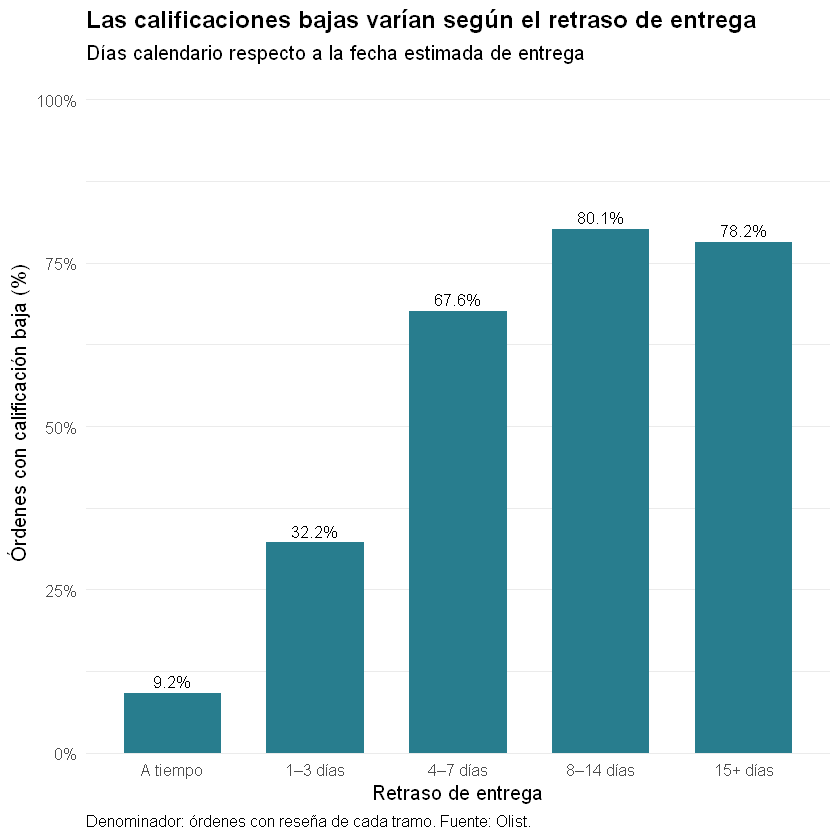

In [11]:
grafico_retraso <- ggplot(
  resumen_retraso, aes(x = tramo_retraso, y = tasa_baja)
) +
  geom_col(fill = "#287D8E", width = 0.68) +
  geom_text(
    aes(label = scales::percent(tasa_baja, accuracy = 0.1)),
    vjust = -0.45, size = 3.6
  ) +
  scale_y_continuous(
    labels = scales::label_percent(accuracy = 1),
    limits = c(0, 1), expand = expansion(mult = c(0, 0.04))
  ) +
  labs(
    title = "Las calificaciones bajas varían según el retraso de entrega",
    subtitle = "Días calendario respecto a la fecha estimada de entrega",
    x = "Retraso de entrega", y = "Órdenes con calificación baja (%)",
    caption = "Denominador: órdenes con reseña de cada tramo. Fuente: Olist."
  ) +
  theme(
    plot.title = element_text(face = "bold"),
    panel.grid.major.x = element_blank(),
    plot.caption = element_text(hjust = 0)
  )
print(grafico_retraso)


**Hallazgo.** Entre las entregas a tiempo, **9,2 %** de las órdenes reseñadas tienen calificación baja. La proporción asciende a **67,6 %** cuando la entrega ocurre entre **4 y 7 días** después de la fecha estimada: una diferencia de aproximadamente **58,4 puntos porcentuales**.

La evidencia respalda el retraso como **señal de revisión prioritaria**. La comparación es observacional: no cuantifica cuánto mejoraría la satisfacción si se redujera la demora.


### 4.2. Figura R03 — Flete relativo y calificación baja

El **flete relativo** mide el costo de transporte dividido entre el valor de los productos. Las tasas de calificación baja se comparan entre cuatro tramos. El gráfico parte de cero para hacer visibles diferencias sin amplificarlas artificialmente.


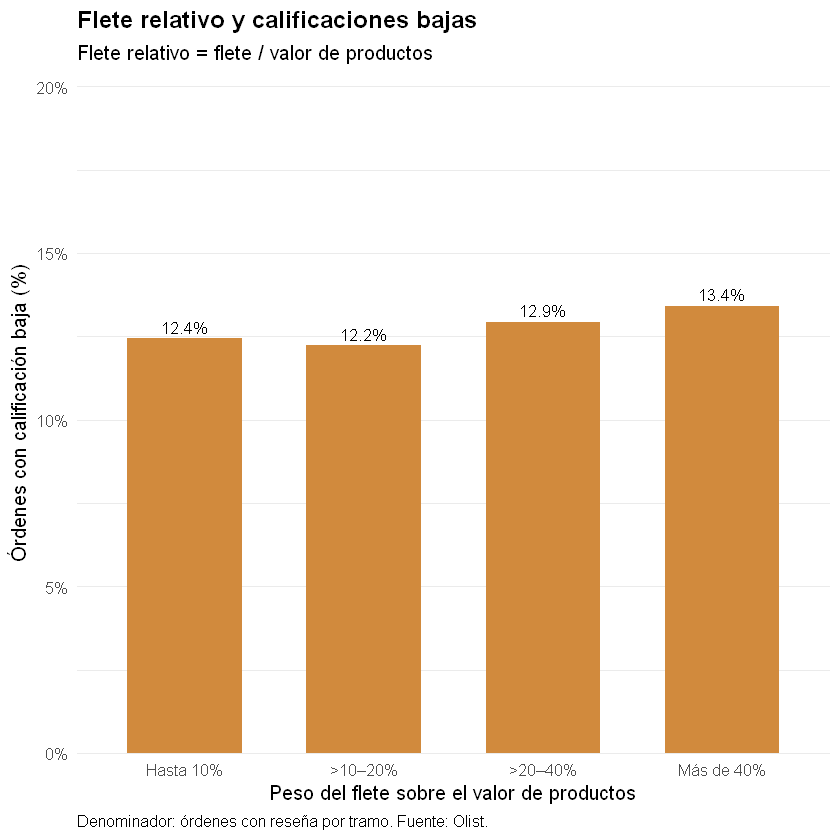

In [12]:
grafico_flete <- ggplot(
  resumen_flete, aes(x = tramo_flete, y = tasa_baja)
) +
  geom_col(fill = "#D18A3D", width = 0.64) +
  geom_text(
    aes(label = scales::percent(tasa_baja, accuracy = 0.1)),
    vjust = -0.45, size = 3.6
  ) +
  scale_y_continuous(
    labels = scales::label_percent(accuracy = 1),
    limits = c(0, max(0.20, max(resumen_flete$tasa_baja, na.rm = TRUE) * 1.15)),
    expand = expansion(mult = c(0, 0.02))
  ) +
  labs(
    title = "Flete relativo y calificaciones bajas",
    subtitle = "Flete relativo = flete / valor de productos",
    x = "Peso del flete sobre el valor de productos", y = "Órdenes con calificación baja (%)",
    caption = "Denominador: órdenes con reseña por tramo. Fuente: Olist."
  ) +
  theme(
    plot.title = element_text(face = "bold"),
    panel.grid.major.x = element_blank(),
    plot.caption = element_text(hjust = 0)
  )
print(grafico_flete)


**Hallazgo.** La tasa de calificaciones bajas oscila aproximadamente entre **12,2 % y 13,4 %** según el tramo de flete relativo; el recorrido es de **1,2 puntos porcentuales**. La variación es pequeña frente a la observada por retraso de entrega.

En consecuencia, el flete relativo se conserva como indicador contextual, pero esta evidencia por sí sola **no justifica asignarle un peso elevado** en una regla de prioridad.


### 4.3. Asociación numérica y valor comercial

Calculamos el coeficiente **ρ de Spearman** para examinar la asociación monotónica de la calificación con los días totales de entrega, los días de retraso, el flete relativo y el valor de productos. Cada estimación utiliza pares válidos de observaciones.

Además, los cuartiles de valor de compra y el resumen mensual ofrecen contexto sobre la exposición comercial y la evolución temporal, sin introducir nuevas figuras principales. **Valor de productos no significa utilidad ni pérdida esperada.**


In [13]:
calcular_rho <- function(variable) {
  pares <- base_analisis %>%
    transmute(x = .data[[variable]], y = satisfaccion) %>%
    filter(is.finite(x), is.finite(y))
  rho <- if (nrow(pares) >= 3 && n_distinct(pares$x) > 1 && n_distinct(pares$y) > 1) {
    cor(pares$x, pares$y, method = "spearman")
  } else NA_real_
  tibble(variable = variable, pares = nrow(pares), rho = rho)
}

variables <- c("dias_entrega", "dias_retraso", "flete_relativo", "valor_productos")
correlaciones <- purrr::map_dfr(variables, calcular_rho) %>%
  mutate(indicador = recode(variable,
    dias_entrega = "Días totales de entrega",
    dias_retraso = "Días de retraso",
    flete_relativo = "Flete relativo",
    valor_productos = "Valor de productos (R$)"
  )) %>%
  select(indicador, variable, pares, rho)
print(correlaciones, n = Inf)

resumen_mensual <- base_analisis %>%
  group_by(mes) %>%
  summarise(
    ordenes = n(), valor_productos = sum(valor_productos), flete = sum(flete),
    satisfaccion_media = mean(satisfaccion, na.rm = TRUE),
    con_resena = sum(!is.na(satisfaccion)),
    tasa_tardia = mean(entrega_tardia),
    .groups = "drop"
  )
cat("\nContexto mensual (primeros seis meses):\n")
print(head(resumen_mensual, 6))


# A tibble: 4 × 4
  indicador               variable        pares     rho
  <chr>                   <chr>           <int>   <dbl>
1 Días totales de entrega dias_entrega    95560 -0.235 
2 Días de retraso         dias_retraso    95560 -0.315 
3 Flete relativo          flete_relativo  95560 -0.0308
4 Valor de productos (R$) valor_productos 95560 -0.0293

Contexto mensual (primeros seis meses):
# A tibble: 6 × 7
  mes        ordenes valor_productos  flete satisfaccion_media con_resena tasa_tardia
  <date>       <int>           <dbl>  <dbl>              <dbl>      <int>       <dbl>
1 2017-01-01     750         111798. 15684.               4.20        741      0.0293
2 2017-02-01    1653         234223. 37016.               4.20       1643      0.0296
3 2017-03-01    2546         359199. 55132.               4.19       2527      0.0456
4 2017-04-01    2303         340670. 50143.               4.14       2290      0.0656
5 2017-05-01    3545         489159. 77498.               4.24       35

**Hallazgo.** La asociación entre **días de retraso y satisfacción** es negativa (**ρ = −0,315**), mientras que para **flete relativo y satisfacción** es mucho más débil (**ρ = −0,031**). Ambos cálculos se realizaron sobre **95.560 órdenes con reseña válida**.

La magnitud relativa de estas asociaciones, junto con los tramos anteriores, respalda utilizar el retraso como señal operativa principal y tratar el flete como información complementaria. Ninguna correlación demuestra causalidad.


## 5. Síntesis del diagnóstico

Los indicadores siguientes reúnen los resultados que conectan el análisis exploratorio con la decisión posterior. La tabla reproduce las métricas calculadas con la misma cohorte, sin cambiar la unidad de análisis.


In [14]:
# Indicadores centrales del diagnóstico, calculados a partir de la cohorte analítica.
formatear_tasa <- function(x) {
  if (length(x) == 0 || is.na(x[1])) return("s/d")
  scales::percent(x[1], accuracy = 0.1)
}

region_tardias <- resumen_regiones %>%
  filter(region != "Sin región") %>%
  slice_max(tasa_tardia, n = 1, with_ties = FALSE)
region_bajas <- resumen_regiones %>%
  filter(region != "Sin región", !is.na(tasa_baja)) %>%
  slice_max(tasa_baja, n = 1, with_ties = FALSE)
categoria_bajas <- categorias_elegibles %>%
  slice_max(tasa_baja, n = 1, with_ties = FALSE)

rho_retraso <- correlaciones %>%
  filter(variable == "dias_retraso") %>% pull(rho)
rho_flete <- correlaciones %>%
  filter(variable == "flete_relativo") %>% pull(rho)

resumen_para_conclusiones <- tibble(
  indicador = c(
    "Órdenes de la cohorte", "Cobertura de reseñas",
    "Región con mayor tasa de tardías",
    "Región con mayor tasa de bajas",
    "Categoría seleccionada con mayor tasa de bajas",
    "Tasa baja: entregas a tiempo", "Tasa baja: retraso de 4–7 días",
    "Spearman: retraso y satisfacción", "Spearman: flete relativo y satisfacción"
  ),
  resultado = c(
    scales::comma(nrow(base_analisis)),
    formatear_tasa(mean(!is.na(base_analisis$satisfaccion))),
    paste0(region_tardias$region[1], " (", formatear_tasa(region_tardias$tasa_tardia), ")"),
    paste0(region_bajas$region[1], " (", formatear_tasa(region_bajas$tasa_baja), ")"),
    paste0(categoria_bajas$categoria_orden[1], " (", formatear_tasa(categoria_bajas$tasa_baja), ")"),
    formatear_tasa(resumen_retraso$tasa_baja[resumen_retraso$tramo_retraso == "A tiempo"]),
    formatear_tasa(resumen_retraso$tasa_baja[resumen_retraso$tramo_retraso == "4–7 días"]),
    if (is.na(rho_retraso[1])) "s/d" else sprintf("%.3f", rho_retraso[1]),
    if (is.na(rho_flete[1])) "s/d" else sprintf("%.3f", rho_flete[1])
  )
)

print(resumen_para_conclusiones, n = Inf)


# A tibble: 9 × 2
  indicador                                      resultado               
  <chr>                                          <chr>                   
1 Órdenes de la cohorte                          96,203                  
2 Cobertura de reseñas                           99.3%                   
3 Región con mayor tasa de tardías               Nordeste (12.8%)        
4 Región con mayor tasa de bajas                 Nordeste (16.8%)        
5 Categoría seleccionada con mayor tasa de bajas office_furniture (21.7%)
6 Tasa baja: entregas a tiempo                   9.2%                    
7 Tasa baja: retraso de 4–7 días                 67.6%                   
8 Spearman: retraso y satisfacción               -0.315                  
9 Spearman: flete relativo y satisfacción        -0.031                  


### Conclusiones del análisis exploratorio

1. **Concentración territorial y por categoría.** Nordeste presenta las mayores tasas relativas de retraso e insatisfacción entre las macrorregiones. Office furniture destaca por la mayor tasa de bajas entre las categorías seleccionadas, mientras que grupos de mayor volumen pueden acumular más casos aun con tasas menores.
2. **Logística y experiencia.** Las calificaciones bajas aumentan de **9,2 %** en entregas a tiempo a **67,6 %** en retrasos de 4–7 días; la correlación con los días de retraso es **ρ = −0,315**. El incumplimiento logístico emerge como una señal descriptiva relevante para la atención.
3. **Flete y exposición comercial.** El flete relativo muestra una asociación débil con satisfacción (**ρ = −0,031**), por lo que se conserva como contexto. El valor de compra permite dimensionar el alcance comercial de una revisión, sin representar rentabilidad ni pérdidas.

**Implicación de negocio.** La evidencia permite sustentar una política transparente basada principalmente en **retraso**, **satisfacción reportada** y **valor de productos**. La vista por orden se transfiere a Python para calcular prioridades y acciones sugeridas. Los pesos y los umbrales de esa política son decisiones operativas explícitas, no efectos causales estimados.


## 6. Vista analítica y productos del diagnóstico

La entrega principal es una **vista con una fila por orden**, que contiene identificadores, fechas, categoría, región, valor de productos, flete, retraso y satisfacción. La granularidad validada permite que Python aplique reglas sin multiplicar órdenes ni importes.

| Archivo | Contenido |
|---|---|
| `vista_ordenes_python.csv` | Base de órdenes para el análisis operativo |
| `resumen_categorias.csv`, `resumen_regiones.csv` | Tasas y volúmenes de la segmentación |
| `resumen_retraso.csv`, `resumen_flete.csv`, `correlaciones.csv` | Evidencia sobre experiencia y logística |
| `R01_regiones.png`, `R01_categorias.png` | Matrices de concentración por segmento |
| `R02_retraso.png`, `R03_flete.png` | Experiencia según retraso y flete relativo |

También se conservan los controles de calidad, reglas de limpieza, trazabilidad de filtros y demás resúmenes analíticos.


In [15]:
# Entrega principal: una fila por orden para el notebook operativo en Python.
vista_python <- base_analisis %>%
  transmute(
    order_id, customer_id, fecha_compra, mes, customer_state, region,
    categoria_orden, valor_productos, flete, valor_total, flete_relativo,
    dias_entrega, desfase_dias, dias_retraso, entrega_tardia,
    satisfaccion, calificacion_baja, n_items, n_categorias, n_reviews
  )
stopifnot(nrow(vista_python) == n_distinct(vista_python$order_id))

tablas_exportar <- list(
  vista_ordenes_python = vista_python,
  diagnostico_fuentes = diagnostico,
  reglas_limpieza = reglas_limpieza,
  trazabilidad_filtros = filtros,
  resumen_categorias = resumen_categorias,
  resumen_regiones = resumen_regiones,
  resumen_retraso = resumen_retraso,
  resumen_flete = resumen_flete,
  resumen_valor = resumen_valor,
  correlaciones = correlaciones,
  resumen_mensual = resumen_mensual,
  resumen_para_conclusiones = resumen_para_conclusiones
)

purrr::iwalk(tablas_exportar, function(datos, nombre) {
  readr::write_csv(datos, file.path(ruta_salida, paste0(nombre, ".csv")), na = "")
})

figuras <- list(
  R01_categorias = list(grafico = grafico_categorias, ancho = 11, alto = 7.7),
  R01_regiones = list(grafico = grafico_regiones, ancho = 11, alto = 6.1),
  R02_retraso = list(grafico = grafico_retraso, ancho = 10, alto = 5.8),
  R03_flete = list(grafico = grafico_flete, ancho = 10, alto = 5.8)
)

purrr::iwalk(figuras, function(figura, nombre) {
  ggplot2::ggsave(
    file.path(ruta_salida, paste0(nombre, ".png")),
    figura$grafico, width = figura$ancho, height = figura$alto,
    dpi = 180, bg = "white"
  )
})

cat("Tablas CSV:", length(tablas_exportar), "| Gráficos PNG:", length(figuras), "\n")
cat("Carpeta:", normalizePath(ruta_salida), "\n")
cat("Órdenes exportadas a Python:", nrow(vista_python), "\n")


Tablas CSV: 12 | Gráficos PNG: 4 
Carpeta: C:\Users\santi\OneDrive\Documents\Diploma\DataScience_Business\Analytics_Essentials_I\Caso-Integrador-Final\salidas\exploratorio_r 
Órdenes exportadas a Python: 96203 


## 7. Limitaciones y reproducibilidad

- **Alcance retrospectivo:** las órdenes ya fueron entregadas y las reseñas son posteriores a la compra. El diagnóstico no se presenta como alerta en tiempo real.
- **Cobertura de reseñas:** las tasas de calificación baja se calculan sobre órdenes reseñadas; las respuestas ausentes pueden introducir sesgos.
- **Categoría principal:** una orden puede contener productos de distintas categorías y su calificación no puede atribuirse a un artículo concreto.
- **Medición del retraso:** días calendario respecto de la fecha estimada de entrega, no incumplimiento demostrado de un acuerdo contractual individual.
- **Valor comercial:** `price` representa el valor de productos, no utilidad, margen ni pérdida esperada.
- **Carácter asociativo:** las diferencias por segmento y las correlaciones no identifican causas de insatisfacción.

**Origen y trazabilidad.** Datos abiertos de [Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). El procesamiento se desarrolla con `readr`, `dplyr`, `tidyr`, `stringr`, `lubridate`, `ggplot2`, `purrr` y `scales`. Los parámetros de cohorte y las reglas de limpieza quedan documentados en el propio código.

**Continuidad analítica.** El notebook de Python consume `salidas/exploratorio_r/vista_ordenes_python.csv` y realiza la clasificación operativa de las órdenes.


## 8. Indicadores de volumen, concentración y prioridad

Los indicadores se calculan sobre la misma base depurada de pedidos. Se comparan el crecimiento interanual, la experiencia de entrega, la concentración de calificaciones bajas por vendedor y la distribución de prioridades.


In [16]:
if (!requireNamespace("ggplot2", quietly = TRUE)) {
  install.packages("ggplot2", repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages(library(ggplot2))
options(scipen = 999, width = 120)

viz_colores <- c(Alta = "#BB5B49", Media = "#D18A3D", Baja = "#287D8E")
viz_teal <- "#287D8E"
viz_naranja <- "#D18A3D"
viz_tinta <- "#17313D"
viz_numero <- function(x, decimales = 0) {
  formatC(x, format = "f", digits = decimales, big.mark = ".", decimal.mark = ",")
}
viz_porcentaje <- function(x, decimales = 1) paste0(viz_numero(100 * x, decimales), "%")
viz_tema <- function() {
  theme_minimal(base_size = 14) + theme(
    plot.title = element_text(face = "bold", color = viz_tinta, size = 18),
    plot.subtitle = element_text(color = "#59717A", margin = margin(b = 12)),
    plot.caption = element_text(color = "#59717A", size = 10, hjust = 0, margin = margin(t = 12)),
    text = element_text(color = viz_tinta),
    panel.grid.minor = element_blank(),
    legend.position = "top",
    legend.title = element_blank(),
    plot.margin = margin(16, 28, 16, 16)
  )
}



In [17]:
viz_base <- as.data.frame(base_analisis)
viz_filtros <- as.data.frame(filtros)
viz_mensual <- as.data.frame(resumen_mensual)
viz_mensual$mes <- as.character(viz_mensual$mes)
viz_retrasos <- as.data.frame(resumen_retraso)
viz_correlaciones <- as.data.frame(correlaciones)
viz_regiones <- as.data.frame(resumen_regiones)

viz_entregas <- do.call(rbind, lapply(c(FALSE, TRUE), function(tardia) {
  datos <- viz_base[viz_base$entrega_tardia == tardia, ]
  data.frame(
    tipo_entrega = if (tardia) "Tardía" else "A tiempo",
    nota_media = mean(datos$satisfaccion, na.rm = TRUE),
    bajas_pct = 100 * mean(datos$calificacion_baja, na.rm = TRUE)
  )
}))

# Cada calificación baja se reparte entre los vendedores de su pedido.
# El universo de vendedores corresponde a los pedidos con reseña disponible.
viz_puente <- unique(as.data.frame(items[, c("order_id", "seller_id")]))
viz_resenados <- viz_base[!is.na(viz_base$satisfaccion), c("order_id", "calificacion_baja")]
viz_puente <- merge(viz_resenados, viz_puente, by = "order_id", all.x = TRUE)
stopifnot(!anyNA(viz_puente$seller_id),
          !anyDuplicated(viz_puente[c("order_id", "seller_id")]))
viz_puente$n_vendedores <- ave(rep(1, nrow(viz_puente)), viz_puente$order_id, FUN = sum)
viz_puente$bajas_asignadas <- as.numeric(viz_puente$calificacion_baja) / viz_puente$n_vendedores
viz_pareto <- aggregate(bajas_asignadas ~ seller_id, data = viz_puente, FUN = sum)
viz_pareto <- viz_pareto[order(-viz_pareto$bajas_asignadas, viz_pareto$seller_id), ]
viz_pareto$posicion <- seq_len(nrow(viz_pareto))
viz_pareto$cuota <- viz_pareto$bajas_asignadas / sum(viz_pareto$bajas_asignadas)
viz_pareto$acumulado <- cumsum(viz_pareto$cuota)
viz_pareto$grupos_acumulados <- viz_pareto$posicion / nrow(viz_pareto)

# Regla de prioridad: satisfacción baja +2, retraso de 4 días o más +2,
# retraso de 1 a 3 días +1 y valor de productos desde el percentil 75 +1.
viz_umbral_valor <- as.numeric(quantile(viz_base$valor_productos, 0.75, type = 7))
viz_puntos_nota <- ifelse(is.na(viz_base$calificacion_baja), 0L,
                         ifelse(viz_base$calificacion_baja, 2L, 0L))
viz_puntos_retraso <- ifelse(viz_base$dias_retraso >= 4, 2L,
                            ifelse(viz_base$dias_retraso > 0, 1L, 0L))
viz_puntos_valor <- as.integer(viz_base$valor_productos >= viz_umbral_valor)
viz_puntaje <- viz_puntos_nota + viz_puntos_retraso + viz_puntos_valor
viz_nivel <- ifelse(viz_puntaje >= 3, "Alta", ifelse(viz_puntaje > 0, "Media", "Baja"))
viz_prioridades <- do.call(rbind, lapply(c("Alta", "Media", "Baja"), function(nivel) {
  elegido <- viz_nivel == nivel
  data.frame(prioridad = nivel, ordenes = sum(elegido),
             valor_productos = sum(viz_base$valor_productos[elegido]))
}))
viz_prioridades$pct_ordenes <- viz_prioridades$ordenes / nrow(viz_base)
viz_prioridades$pct_valor <- viz_prioridades$valor_productos / sum(viz_base$valor_productos)

viz_n <- nrow(viz_base)
viz_con_resena <- sum(!is.na(viz_base$satisfaccion))
stopifnot(
  viz_n == tail(viz_filtros$ordenes, 1),
  sum(viz_mensual$ordenes) == viz_n,
  sum(viz_retrasos$ordenes) == viz_n,
  sum(viz_prioridades$ordenes) == viz_n,
  viz_con_resena == sum(viz_retrasos$con_resena),
  abs(sum(viz_pareto$bajas_asignadas) - sum(viz_base$calificacion_baja, na.rm = TRUE)) < 1e-8,
  isTRUE(all.equal(sum(viz_mensual$valor_productos),
                   sum(viz_prioridades$valor_productos), tolerance = 1e-8))
)
cat("Pedidos: ", viz_numero(viz_n), "; con reseña: ", viz_numero(viz_con_resena),
    "; cobertura: ", viz_porcentaje(viz_con_resena / viz_n), ".\n", sep = "")
cat("Umbral de valor (P75): R$ ", viz_numero(viz_umbral_valor, 2), ".\n", sep = "")


Pedidos: 96.203; con reseña: 95.560; cobertura: 99,3%.


Umbral de valor (P75): R$ 149,90.


### 8.1. Depuración de pedidos

Las barras muestran el número de pedidos que permanece después de cada filtro. La validación final de importes conserva los mismos 96.203 pedidos.


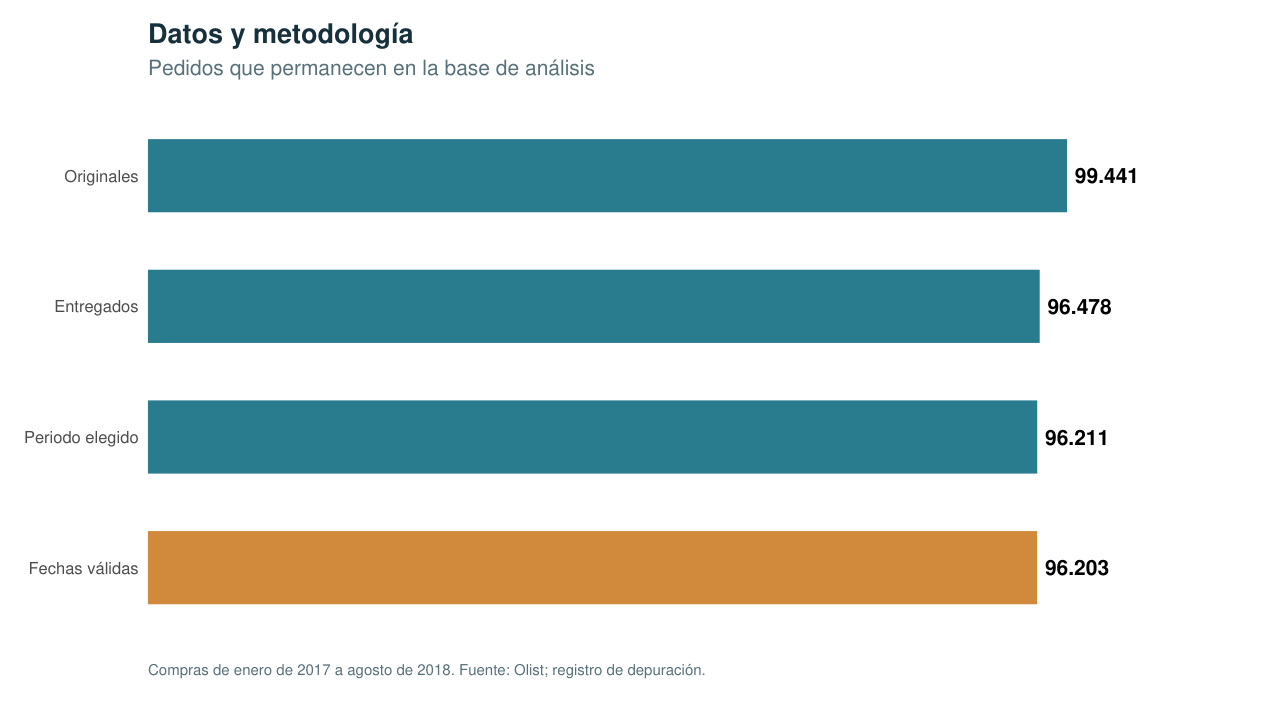

In [18]:
viz_etapas <- viz_filtros[1:4, c("paso", "ordenes")]
viz_etapas$etapa <- factor(c("Originales", "Entregados", "Periodo elegido", "Fechas válidas"),
                          levels = rev(c("Originales", "Entregados", "Periodo elegido", "Fechas válidas")))
viz_etapas$tipo <- ifelse(viz_etapas$etapa == "Fechas válidas", "Final", "Previo")

viz_grafico_01 <- ggplot(viz_etapas, aes(x = ordenes, y = etapa, fill = tipo)) +
  geom_col(width = 0.56, show.legend = FALSE) +
  geom_text(aes(label = viz_numero(ordenes)), hjust = -0.12, size = 5, fontface = "bold") +
  scale_fill_manual(values = c(Previo = viz_teal, Final = viz_naranja)) +
  scale_x_continuous(limits = c(0, max(viz_etapas$ordenes) * 1.18), expand = expansion(mult = c(0, 0))) +
  labs(title = "Datos y metodología", subtitle = "Pedidos que permanecen en la base de análisis",
       x = NULL, y = NULL,
       caption = "Compras de enero de 2017 a agosto de 2018. Fuente: Olist; registro de depuración.") +
  viz_tema() + theme(axis.text.x = element_blank(), panel.grid = element_blank())
print(viz_grafico_01)


### 8.2. Pedidos por mes y crecimiento interanual

Se compara enero a agosto de 2017 y 2018 sobre la cohorte final. Se calculan las variaciones en pedidos, valor vendido y ticket promedio. El valor vendido corresponde a productos, sin flete.


       indicador crecimiento


         Pedidos     +139,9%


   Valor vendido     +141,1%


 Ticket promedio       +0,5%


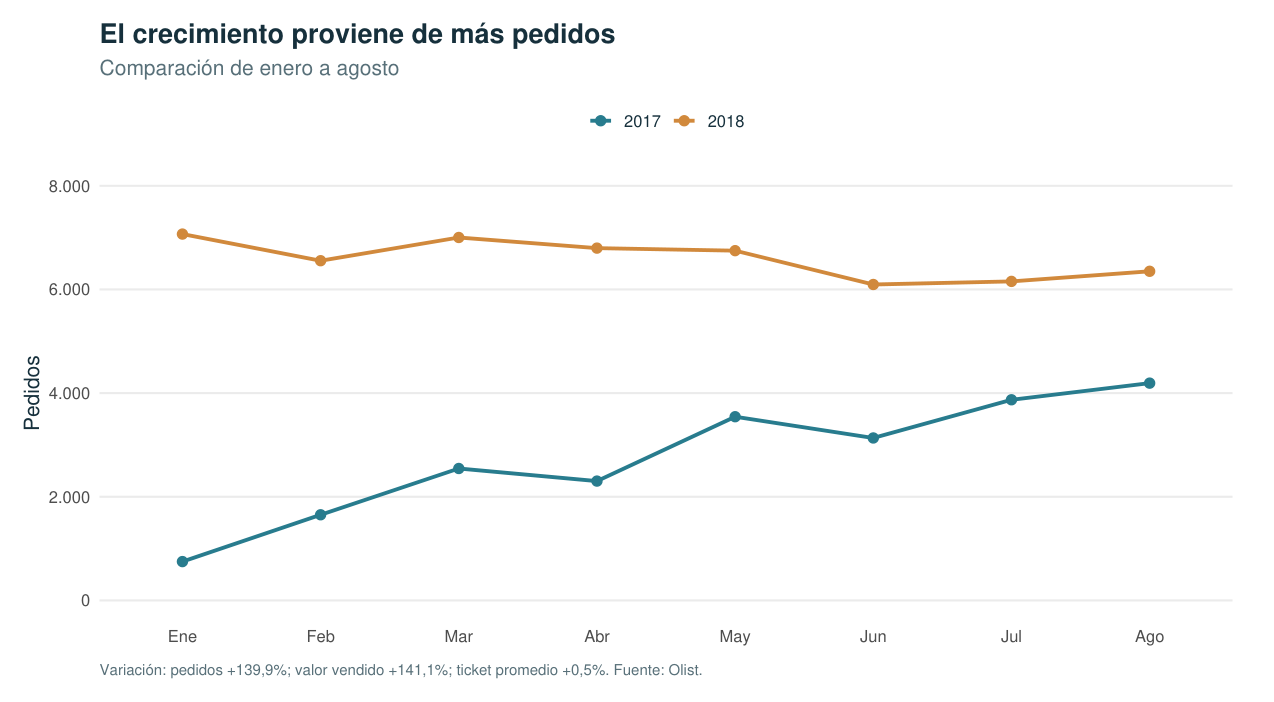

In [19]:
viz_anio <- substr(viz_mensual$mes, 1, 4)
viz_mes_num <- as.integer(substr(viz_mensual$mes, 6, 7))
viz_2017 <- viz_mensual[viz_anio == "2017" & viz_mes_num <= 8, ]
viz_2018 <- viz_mensual[viz_anio == "2018" & viz_mes_num <= 8, ]
viz_2017 <- viz_2017[order(viz_2017$mes), ]
viz_2018 <- viz_2018[order(viz_2018$mes), ]
stopifnot(nrow(viz_2017) == 8, nrow(viz_2018) == 8)
viz_meses <- c("Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago")
viz_evolucion <- data.frame(
  mes = factor(rep(viz_meses, 2), levels = viz_meses),
  anio = rep(c("2017", "2018"), each = 8),
  pedidos = c(viz_2017$ordenes, viz_2018$ordenes)
)
viz_ticket_2017 <- sum(viz_2017$valor_productos) / sum(viz_2017$ordenes)
viz_ticket_2018 <- sum(viz_2018$valor_productos) / sum(viz_2018$ordenes)
viz_crecimiento <- data.frame(
  indicador = c("Pedidos", "Valor vendido", "Ticket promedio"),
  variacion = c(sum(viz_2018$ordenes) / sum(viz_2017$ordenes) - 1,
                sum(viz_2018$valor_productos) / sum(viz_2017$valor_productos) - 1,
                viz_ticket_2018 / viz_ticket_2017 - 1)
)
print(data.frame(indicador = viz_crecimiento$indicador,
                 crecimiento = paste0("+", viz_porcentaje(viz_crecimiento$variacion))), row.names = FALSE)

viz_grafico_02 <- ggplot(viz_evolucion, aes(x = mes, y = pedidos, color = anio, group = anio)) +
  geom_line(linewidth = 1.2) + geom_point(size = 2.7) +
  scale_color_manual(values = c(`2017` = viz_teal, `2018` = viz_naranja)) +
  scale_y_continuous(limits = c(0, 8000), breaks = seq(0, 8000, 2000), labels = viz_numero) +
  labs(title = "El crecimiento proviene de más pedidos", subtitle = "Comparación de enero a agosto",
       x = NULL, y = "Pedidos",
       caption = "Variación: pedidos +139,9%; valor vendido +141,1%; ticket promedio +0,5%. Fuente: Olist.") +
  viz_tema() + theme(panel.grid.major.x = element_blank())
print(viz_grafico_02)


### 8.3. Calificaciones bajas según el retraso

Una calificación baja es una nota media de dos o menos. Cada porcentaje utiliza los pedidos **con reseña** de su tramo. El retraso se mide en días calendario después de la fecha prometida.


  entrega calificacion_media bajas


 A tiempo               4.29  9,2%


   Tardía               2.27 62,4%


               indicador pares         rho


 Días totales de entrega 95560 -0.23467079


         Días de retraso 95560 -0.31489121


          Flete relativo 95560 -0.03081599


 Valor de productos (R$) 95560 -0.02925544


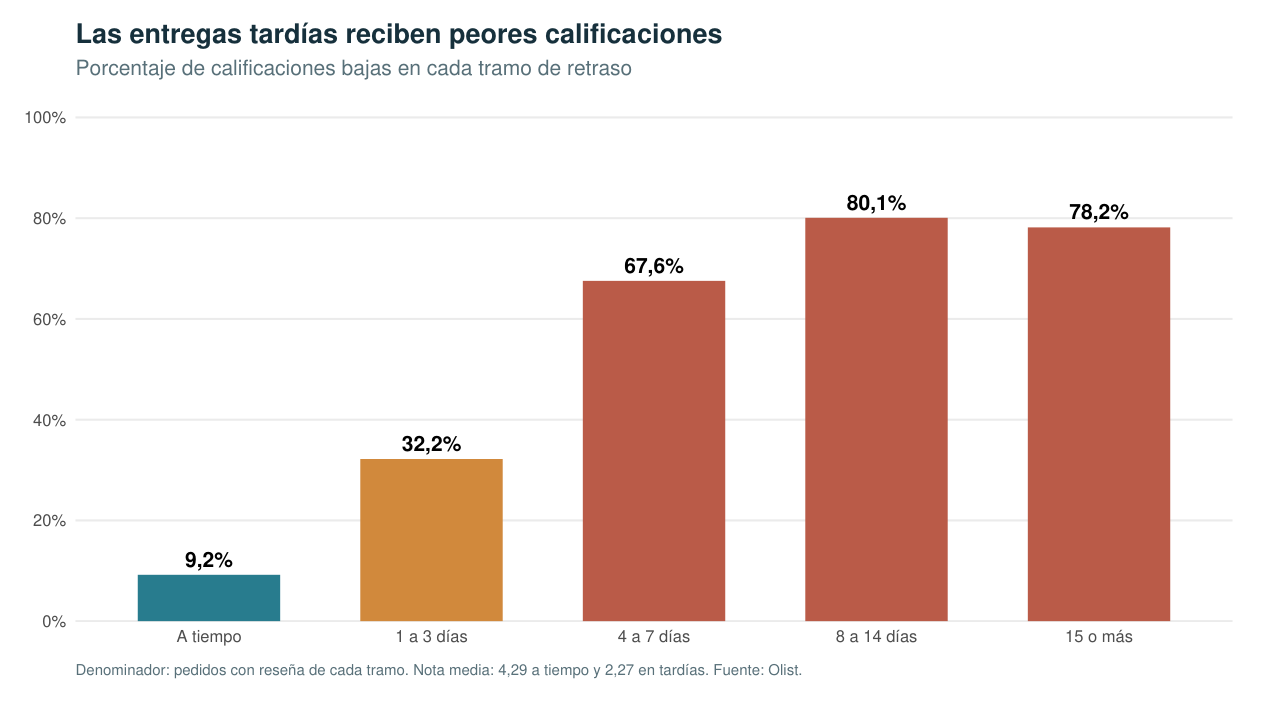

In [20]:
viz_tramos <- c("A tiempo", "1 a 3 días", "4 a 7 días", "8 a 14 días", "15 o más")
stopifnot(nrow(viz_retrasos) == 5)
viz_retrasos$tramo <- factor(viz_tramos, levels = viz_tramos)
viz_retrasos$tramo_color <- factor(viz_tramos, levels = viz_tramos)
viz_color_tramos <- setNames(c(viz_teal, viz_naranja, rep(viz_colores["Alta"], 3)), viz_tramos)

print(data.frame(entrega = viz_entregas$tipo_entrega,
                 calificacion_media = round(viz_entregas$nota_media, 2),
                 bajas = paste0(viz_numero(viz_entregas$bajas_pct, 1), "%")), row.names = FALSE)
print(viz_correlaciones[, c("indicador", "pares", "rho")], row.names = FALSE)

viz_grafico_03 <- ggplot(viz_retrasos, aes(x = tramo, y = tasa_baja, fill = tramo_color)) +
  geom_col(width = 0.64, show.legend = FALSE) +
  geom_text(aes(label = viz_porcentaje(tasa_baja)), vjust = -0.55, size = 5, fontface = "bold") +
  scale_fill_manual(values = viz_color_tramos) +
  scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2),
                     labels = function(x) viz_porcentaje(x, 0), expand = expansion(mult = c(0, 0.04))) +
  labs(title = "Las entregas tardías reciben peores calificaciones",
       subtitle = "Porcentaje de calificaciones bajas en cada tramo de retraso",
       x = NULL, y = NULL,
       caption = "Denominador: pedidos con reseña de cada tramo. Nota media: 4,29 a tiempo y 2,27 en tardías. Fuente: Olist.") +
  viz_tema() + theme(panel.grid.major.x = element_blank())
print(viz_grafico_03)


### 8.4. Concentración de casos por vendedor

Cuando un pedido tiene varios vendedores, se reparte el caso entre ellos antes de acumular. Por eso el gráfico se refiere a **casos asignados**. El ranking orienta una investigación y no establece responsabilidad causal individual.

Se incluyen únicamente pedidos con reseña disponible. La suma de casos asignados coincide con el total de pedidos con calificación baja.


Vendedores: 2.941; corte del 80%: 427 (14,5%).


Primeros 20 vendedores: 23,8% de los casos asignados.


Nordeste: 16,8% de calificaciones bajas.


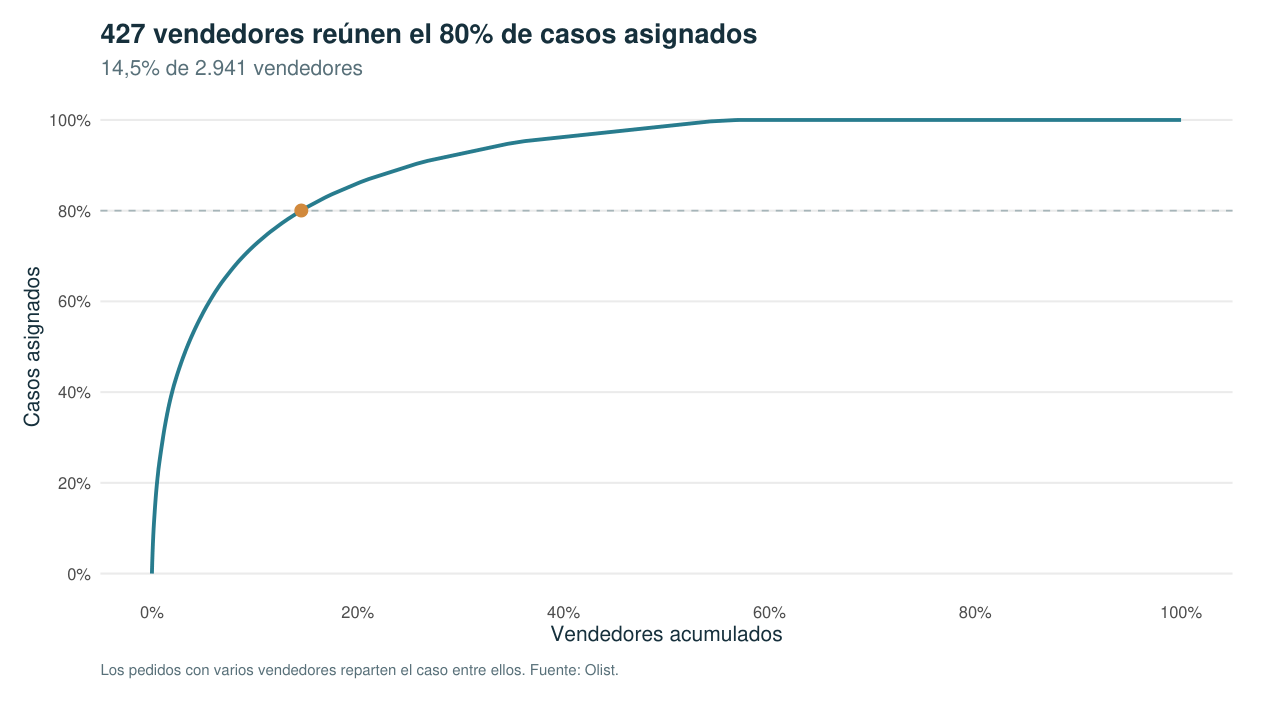

In [21]:
viz_pareto <- viz_pareto[order(viz_pareto$posicion), ]
viz_corte <- viz_pareto[which(viz_pareto$acumulado >= 0.8)[1], ]
viz_curva <- rbind(data.frame(vendedores = 0, casos = 0),
                    data.frame(vendedores = viz_pareto$grupos_acumulados, casos = viz_pareto$acumulado))
viz_top20 <- viz_pareto$acumulado[20]
viz_ne <- viz_regiones[viz_regiones$region == "Nordeste", ]
cat("Vendedores: ", viz_numero(nrow(viz_pareto)), "; corte del 80%: ", viz_corte$posicion,
    " (", viz_porcentaje(viz_corte$grupos_acumulados), ").\n", sep = "")
cat("Primeros 20 vendedores: ", viz_porcentaje(viz_top20), " de los casos asignados.\n", sep = "")
cat("Nordeste: ", viz_porcentaje(viz_ne$tasa_baja), " de calificaciones bajas.\n", sep = "")

viz_grafico_04 <- ggplot(viz_curva, aes(x = vendedores, y = casos)) +
  geom_hline(yintercept = 0.8, linetype = 2, color = "#A6B5BA", linewidth = 0.55) +
  geom_line(color = viz_teal, linewidth = 1.2) +
  geom_point(data = data.frame(vendedores = viz_corte$grupos_acumulados, casos = viz_corte$acumulado),
             color = viz_naranja, size = 3.5) +
  scale_x_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2), labels = function(x) viz_porcentaje(x, 0)) +
  scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.2), labels = function(x) viz_porcentaje(x, 0)) +
  labs(title = paste(viz_corte$posicion, "vendedores reúnen el 80% de casos asignados"),
       subtitle = paste0(viz_porcentaje(viz_corte$grupos_acumulados), " de ", viz_numero(nrow(viz_pareto)), " vendedores"),
       x = "Vendedores acumulados", y = "Casos asignados",
       caption = "Los pedidos con varios vendedores reparten el caso entre ellos. Fuente: Olist.") +
  viz_tema() + theme(panel.grid.major.x = element_blank())
print(viz_grafico_04)


### 8.5. Distribución de prioridades y valor comercial

Cada barra suma el 100% de su propia dimensión. El valor comercial corresponde al precio de productos y ya forma parte del puntaje de la política de priorización.

La regla asigna dos puntos por calificación baja, dos por retraso de cuatro días o más (o uno por retraso de uno a tres días) y uno por valor desde el percentil 75. Los niveles son Alta (3–5 puntos), Media (1–2) y Baja (0). Los pesos y umbrales representan criterios de gestión, no efectos causales estimados.


 prioridad pedidos porcentaje_pedidos porcentaje_valor


      Alta    6926               7,2%            12,8%


     Media   27928              29,0%            55,6%


      Baja   61349              63,8%            31,6%


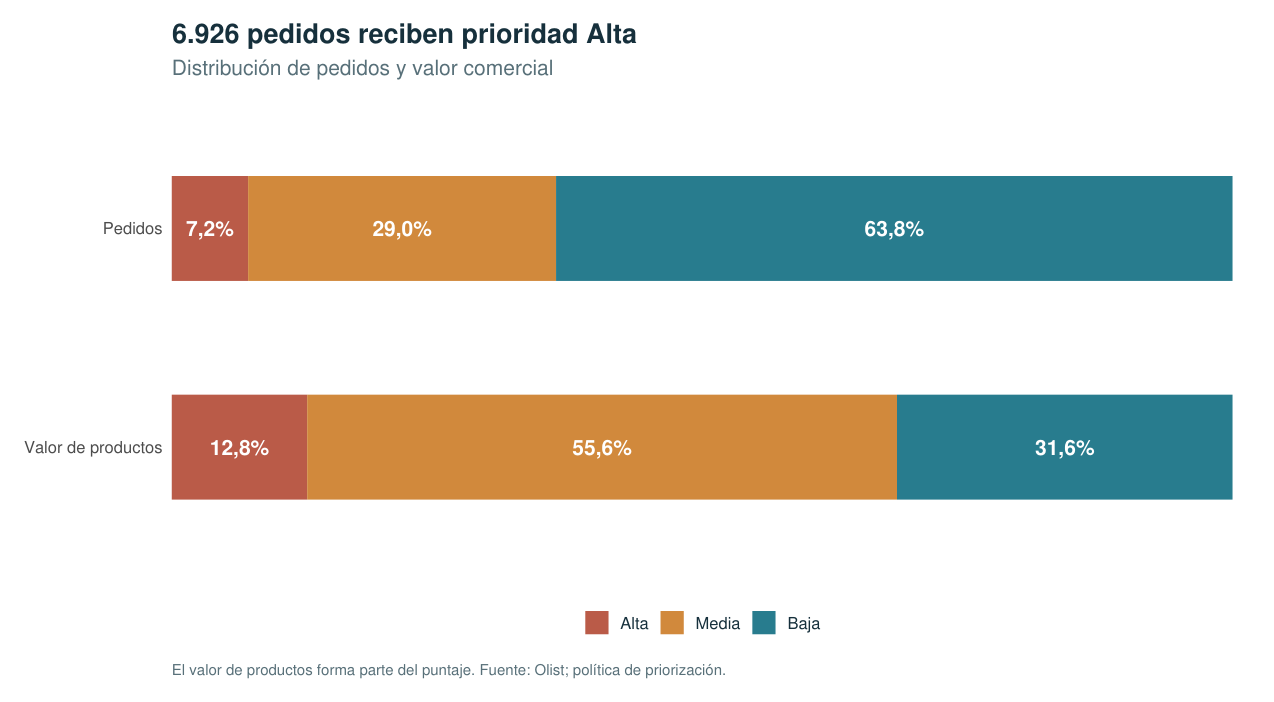

In [22]:
viz_prioridades <- viz_prioridades[match(c("Alta", "Media", "Baja"), viz_prioridades$prioridad), ]
stopifnot(abs(sum(viz_prioridades$pct_ordenes) - 1) < 1e-8,
          abs(sum(viz_prioridades$pct_valor) - 1) < 1e-8)
viz_prioridades_largo <- data.frame(
  dimension = factor(rep(c("Pedidos", "Valor de productos"), each = 3),
                     levels = c("Valor de productos", "Pedidos")),
  prioridad = factor(rep(viz_prioridades$prioridad, 2), levels = c("Alta", "Media", "Baja")),
  proporcion = c(viz_prioridades$pct_ordenes, viz_prioridades$pct_valor)
)
print(data.frame(prioridad = viz_prioridades$prioridad,
                 pedidos = viz_prioridades$ordenes,
                 porcentaje_pedidos = viz_porcentaje(viz_prioridades$pct_ordenes),
                 porcentaje_valor = viz_porcentaje(viz_prioridades$pct_valor)), row.names = FALSE)

viz_grafico_05 <- ggplot(viz_prioridades_largo, aes(x = dimension, y = proporcion, fill = prioridad)) +
  geom_col(width = 0.48, position = position_stack(reverse = TRUE)) +
  geom_text(aes(label = viz_porcentaje(proporcion)),
             position = position_stack(vjust = 0.5, reverse = TRUE), color = "white", size = 4.8, fontface = "bold") +
  scale_fill_manual(values = viz_colores, breaks = c("Alta", "Media", "Baja")) +
  scale_y_continuous(limits = c(0, 1), expand = expansion(mult = c(0, 0))) +
  coord_flip() +
  labs(title = paste(viz_numero(viz_prioridades$ordenes[viz_prioridades$prioridad == "Alta"]), "pedidos reciben prioridad Alta"), subtitle = "Distribución de pedidos y valor comercial",
       x = NULL, y = NULL,
       caption = "El valor de productos forma parte del puntaje. Fuente: Olist; política de priorización.") +
  viz_tema() + theme(legend.position = "bottom", axis.text.x = element_blank(), panel.grid = element_blank())
print(viz_grafico_05)


### 8.6. Exportación de indicadores

Los cinco gráficos se guardan como PDF vectoriales. También se conservan las tablas de crecimiento, concentración por vendedor y distribución de prioridades.


In [23]:
viz_graficos <- list(
  `01_depuracion` = viz_grafico_01,
  `02_evolucion` = viz_grafico_02,
  `03_retraso` = viz_grafico_03,
  `04_pareto` = viz_grafico_04,
  `05_prioridades` = viz_grafico_05
)
viz_salida <- file.path(ruta_salida, "indicadores_complementarios")
dir.create(viz_salida, recursive = TRUE, showWarnings = FALSE)
for (viz_nombre in names(viz_graficos)) {
  ggsave(file.path(viz_salida, paste0(viz_nombre, ".pdf")),
         plot = viz_graficos[[viz_nombre]], width = 11.8, height = 6.5,
         units = "in", device = "pdf", useDingbats = FALSE, useKerning = FALSE)
}
write.csv(viz_crecimiento, file.path(viz_salida, "crecimiento_interanual.csv"), row.names = FALSE)
write.csv(viz_pareto, file.path(viz_salida, "pareto_vendedores.csv"), row.names = FALSE)
write.csv(viz_prioridades, file.path(viz_salida, "distribucion_prioridades.csv"), row.names = FALSE)
cat("Cinco gráficos PDF y tres tablas CSV exportados.\n")


Cinco gráficos PDF y tres tablas CSV exportados.
